# Session 5: Exact Sampling Distributions: Chi-Square, t, Z and F Tests

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    pass  # numpy, pandas, scipy, statsmodels and matplotlib are preinstalled in Colab
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/03-inferential-statistical-analysis/code/'
    for f in []:
        if not os.path.exists(f):
            subprocess.run(['wget', '-q', base + f], check=False)
print('ready')

ready


## Example: `session-05_chi_square.py`

In [2]:
"""
Session 5 · Example 1: Chi-square tests (goodness of fit and independence)
------------------------------------------------------------------------
  chi2 = sum (Observed - Expected)^2 / Expected

1. Goodness of fit: is a die fair? Do weekly orders follow the expected pattern?
2. Test of independence: is preferred payment method related to age group?
   Expected counts are computed by hand: E = row total * column total / grand total.
3. Effect size: Cramer's V.

Run:  python session-05_chi_square.py
"""
import numpy as np
import pandas as pd
from scipy import stats

# ---- 1a. Goodness of fit: 120 rolls of a die ----------------------------------------
obs = np.array([16, 25, 17, 14, 28, 20])
exp = np.full(6, obs.sum() / 6)
chi2 = ((obs - exp) ** 2 / exp).sum()
df = len(obs) - 1
print("1a) Is the die fair?  H0: every face has probability 1/6")
print("    observed:", obs.tolist(), " expected: 20 each")
print(f"    chi2 = {chi2:.3f}, df = {df}, critical (alpha .05) = {stats.chi2.ppf(0.95, df):.3f}, "
      f"p = {stats.chi2.sf(chi2, df):.4f}")
print("    scipy:", tuple(round(float(v), 4) for v in stats.chisquare(obs, exp)))

# ---- 1b. Goodness of fit with unequal expected proportions --------------------------
# A cafe plans staff assuming 10% of weekly orders Mon-Thu each, 20% Fri, 20% Sat, 20% Sun.
orders = np.array([52, 48, 61, 45, 98, 120, 76])
props = np.array([0.10, 0.10, 0.10, 0.10, 0.20, 0.20, 0.20])
res = stats.chisquare(orders, props * orders.sum())
print(f"\n1b) Weekly order pattern: chi2 = {res.statistic:.2f}, p = {res.pvalue:.4f} "
      f"-> {'pattern differs from the plan' if res.pvalue < 0.05 else 'consistent with the plan'}")
print("    largest contributions:", dict(zip(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
      [round(float(v), 1) for v in (orders - props * orders.sum()) ** 2 / (props * orders.sum())])))

# ---- 2. Test of independence --------------------------------------------------------
table = pd.DataFrame([[48, 30, 22], [35, 42, 28], [18, 28, 49]],
                     index=["18-25", "26-40", "41+"], columns=["Wallet app", "Card", "Cash"])
print("\n2) Payment method by age group (observed)")
print(table.to_string())
row, col, N = table.sum(axis=1).values, table.sum(axis=0).values, table.values.sum()
expected = np.outer(row, col) / N
chi2 = ((table.values - expected) ** 2 / expected).sum()
dof = (table.shape[0] - 1) * (table.shape[1] - 1)
print("Expected counts if independent:")
print(pd.DataFrame(expected.round(1), index=table.index, columns=table.columns).to_string())
print(f"chi2 = {chi2:.3f}, df = {dof}, p = {stats.chi2.sf(chi2, dof):.6f}")
c2, p, d, _ = stats.chi2_contingency(table)
print(f"scipy chi2_contingency: chi2 = {c2:.3f}, p = {p:.6f}, df = {d}")

# ---- 3. Effect size -------------------------------------------------------------------
V = np.sqrt(chi2 / (N * (min(table.shape) - 1)))
print(f"Cramer's V = {V:.3f}  (about 0.1 small, 0.3 medium, 0.5 large)")

1a) Is the die fair?  H0: every face has probability 1/6
    observed: [16, 25, 17, 14, 28, 20]  expected: 20 each
    chi2 = 7.500, df = 5, critical (alpha .05) = 11.070, p = 0.1860
    scipy: (7.5, 0.186)

1b) Weekly order pattern: chi2 = 12.88, p = 0.0450 -> pattern differs from the plan
    largest contributions: {'Mon': 0.1, 'Tue': 0.1, 'Wed': 2.4, 'Thu': 0.5, 'Fri': 0.0, 'Sat': 4.0, 'Sun': 5.8}

2) Payment method by age group (observed)
       Wallet app  Card  Cash
18-25          48    30    22
26-40          35    42    28
41+            18    28    49
Expected counts if independent:
       Wallet app  Card  Cash
18-25        33.7  33.3  33.0
26-40        35.4  35.0  34.6
41+          32.0  31.7  31.4
chi2 = 29.257, df = 4, p = 0.000007
scipy chi2_contingency: chi2 = 29.257, p = 0.000007, df = 4
Cramer's V = 0.221  (about 0.1 small, 0.3 medium, 0.5 large)


## Example: `session-05_t_tests.py`

In [3]:
"""
Session 5 · Example 2: The three t tests
---------------------------------------
1. One-sample t test   - is the mean equal to a target value?
2. Independent two-sample t test (Student's pooled and Welch's) - do two groups differ?
3. Paired t test       - did the same people change between 'before' and 'after'?
Each test is done by hand and checked with SciPy. Cohen's d is reported as
the effect size. Chart of t vs normal tails: session-05_t_tests.png

Run:  python session-05_t_tests.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---- 1. One-sample: average sleep of 10 students vs the recommended 8 h -------------
sleep = np.array([6.5, 7.0, 5.5, 8.0, 6.0, 7.5, 6.5, 5.0, 7.0, 6.5])
t1 = (sleep.mean() - 8) / (sleep.std(ddof=1) / np.sqrt(len(sleep)))
print(f"1) One-sample: mean = {sleep.mean():.2f} h, t = {t1:.3f}, df = {len(sleep) - 1}, "
      f"p = {2 * stats.t.sf(abs(t1), len(sleep) - 1):.5f}")
print("   scipy:", round(float(stats.ttest_1samp(sleep, 8).pvalue), 5))

# ---- 2. Independent: marks with online vs classroom teaching -------------------------
online = np.array([68, 72, 65, 70, 74, 69, 71, 66, 73, 67, 70, 72])
classroom = np.array([75, 78, 72, 80, 74, 77, 79, 73, 76, 81])
n1, n2 = len(online), len(classroom)
m1, m2 = online.mean(), classroom.mean()
v1, v2 = online.var(ddof=1), classroom.var(ddof=1)
sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)            # pooled variance
t_pooled = (m1 - m2) / np.sqrt(sp2 * (1 / n1 + 1 / n2))
se_w = np.sqrt(v1 / n1 + v2 / n2)                                  # Welch: no equal-variance assumption
t_welch = (m1 - m2) / se_w
df_w = se_w ** 4 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))   # Welch-Satterthwaite df
d = (m1 - m2) / np.sqrt(sp2)
print(f"\n2) Independent: online mean {m1:.2f}, classroom mean {m2:.2f}")
print(f"   Student (pooled): t = {t_pooled:.3f}, df = {n1 + n2 - 2}, "
      f"p = {2 * stats.t.sf(abs(t_pooled), n1 + n2 - 2):.6f}")
print(f"   Welch:            t = {t_welch:.3f}, df = {df_w:.2f}, p = {2 * stats.t.sf(abs(t_welch), df_w):.6f}")
print(f"   scipy Welch p = {stats.ttest_ind(online, classroom, equal_var=False).pvalue:.6f}")
print(f"   Levene test for equal variances: p = {stats.levene(online, classroom).pvalue:.3f}")
print(f"   Cohen's d = {d:.2f}  (0.2 small, 0.5 medium, 0.8 large)")

# ---- 3. Paired: typing speed (wpm) before and after a 2-week course ---------------
before = np.array([32, 41, 28, 35, 45, 30, 38, 33, 40, 29])
after = np.array([38, 44, 35, 37, 52, 36, 41, 39, 43, 33])
diff = after - before
t3 = diff.mean() / (diff.std(ddof=1) / np.sqrt(len(diff)))
print(f"\n3) Paired: mean gain = {diff.mean():.1f} wpm, sd of gains = {diff.std(ddof=1):.3f}, t = {t3:.3f}, "
      f"p = {2 * stats.t.sf(abs(t3), len(diff) - 1):.7f}")
print(f"   scipy ttest_rel p = {stats.ttest_rel(after, before).pvalue:.7f}")
wrong = stats.ttest_ind(after, before).pvalue
print(f"   WRONG analysis (treating them as independent groups): p = {wrong:.4f}  <- pairing matters!")

# ---- Chart: t distributions vs the standard normal --------------------------------
xs = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(xs, stats.norm.pdf(xs), color="#0A0716", lw=2, label="standard normal (z)")
for dfv, c in [(2, "#F43F5E"), (5, "#FF6B1A"), (30, "#A78BFA")]:
    ax.plot(xs, stats.t.pdf(xs, dfv), color=c, ls="--", label=f"t, df = {dfv}")
ax.set_title("t distributions have heavier tails for small samples"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("session-05_t_tests.png", dpi=100)
print("\nCritical values (two-tailed 5%): z = 1.960, " +
      ", ".join(f"t(df={k}) = {stats.t.ppf(0.975, k):.3f}" for k in (2, 5, 30)))
print("Saved chart: session-05_t_tests.png")

1) One-sample: mean = 6.55 h, t = -5.118, df = 9, p = 0.00063
   scipy: 0.00063

2) Independent: online mean 69.75, classroom mean 76.50
   Student (pooled): t = -5.395, df = 20, p = 0.000028
   Welch:            t = -5.361, df = 18.75, p = 0.000037
   scipy Welch p = 0.000037
   Levene test for equal variances: p = 0.711
   Cohen's d = -2.31  (0.2 small, 0.5 medium, 0.8 large)

3) Paired: mean gain = 4.7 wpm, sd of gains = 1.889, t = 7.870, p = 0.0000252
   scipy ttest_rel p = 0.0000252
   WRONG analysis (treating them as independent groups): p = 0.0774  <- pairing matters!

Critical values (two-tailed 5%): z = 1.960, t(df=2) = 4.303, t(df=5) = 2.571, t(df=30) = 2.042
Saved chart: session-05_t_tests.png


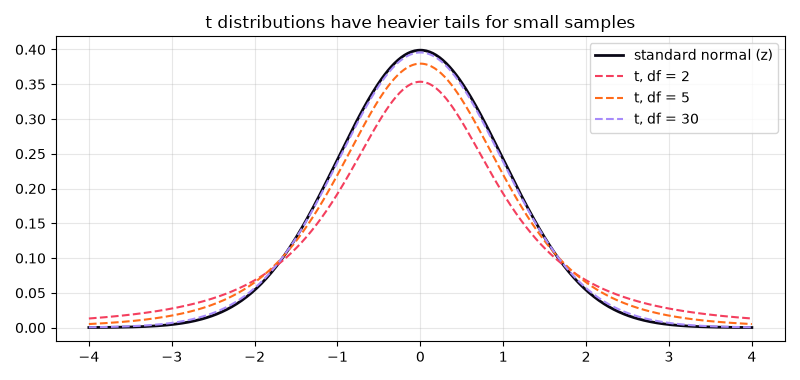

In [4]:
from IPython.display import Image, display
display(Image(filename='session-05_t_tests.png'))  # chart saved by the cell above

## Example: `session-05_z_and_f_tests.py`

In [5]:
"""
Session 5 · Example 3: Z tests and the F test
--------------------------------------------
Z tests use the standard normal distribution and need a KNOWN population sd
(or a large sample, or proportions):
  1. one-sample z test for a mean with known sigma
  2. two-sample z test for proportions
F test compares two VARIANCES (F = s1^2 / s2^2):
  3. are two machines equally consistent?
  4. a chart of F distributions for several degrees of freedom: session-05_z_and_f_tests.png

Run:  python session-05_z_and_f_tests.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---- 1. One-sample z: a flour mill's bags, sigma = 0.15 kg known from years of data -------
n, xbar, mu0, sigma = 50, 9.94, 10.0, 0.15
z = (xbar - mu0) / (sigma / np.sqrt(n))
print(f"1) z = ({xbar} - {mu0}) / ({sigma}/sqrt({n})) = {z:.3f}, two-sided p = {2 * stats.norm.sf(abs(z)):.5f}")

# ---- 2. Two-proportion z: pass rate in two campuses --------------------------------------
x1, n1, x2, n2 = 168, 200, 141, 190
p1, p2 = x1 / n1, x2 / n2
pool = (x1 + x2) / (n1 + n2)
z2 = (p1 - p2) / np.sqrt(pool * (1 - pool) * (1 / n1 + 1 / n2))
print(f"2) Campus A {p1:.1%} vs Campus B {p2:.1%}: z = {z2:.3f}, p = {2 * stats.norm.sf(abs(z2)):.4f}")

# ---- 3. F test for equal variances: fill volumes (ml) from two machines --------------------
m_a = np.array([250.2, 249.8, 250.5, 249.6, 250.1, 250.4, 249.9, 250.0, 250.3, 249.7])
m_b = np.array([251.0, 248.9, 250.8, 249.2, 251.4, 248.6, 250.2, 249.5, 251.1, 248.8, 250.6])
s2a, s2b = m_a.var(ddof=1), m_b.var(ddof=1)
F = s2b / s2a                                   # put the larger variance on top
dfn, dfd = len(m_b) - 1, len(m_a) - 1
p_f = 2 * min(stats.f.sf(F, dfn, dfd), stats.f.cdf(F, dfn, dfd))
print(f"3) Variances: machine A {s2a:.4f}, machine B {s2b:.4f}")
print(f"   F = {F:.3f} with ({dfn}, {dfd}) df; critical F(0.975) = {stats.f.ppf(0.975, dfn, dfd):.3f}; "
      f"two-sided p = {p_f:.5f}")
print("   -> machine B is significantly less consistent" if p_f < 0.05 else "   -> no evidence of a difference")
print(f"   Levene (robust to non-normality) p = {stats.levene(m_a, m_b).pvalue:.5f}")

# ---- 4. Chart of F distributions --------------------------------------------------------
xs = np.linspace(0.01, 5, 400)
fig, ax = plt.subplots(figsize=(8, 3.8))
for (a, b), c in zip([(2, 10), (5, 10), (10, 9), (20, 30)], ["#F43F5E", "#FF6B1A", "#A78BFA", "#0A0716"]):
    ax.plot(xs, stats.f.pdf(xs, a, b), color=c, label=f"F({a}, {b})")
ax.axvline(F, color="#FCD34D", lw=3, label=f"our F = {F:.1f}")
ax.set_title("F distributions are right-skewed and always positive"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("session-05_z_and_f_tests.png", dpi=100)
print("Saved chart: session-05_z_and_f_tests.png")

1) z = (9.94 - 10.0) / (0.15/sqrt(50)) = -2.828, two-sided p = 0.00468
2) Campus A 84.0% vs Campus B 74.2%: z = 2.382, p = 0.0172
3) Variances: machine A 0.0917, machine B 1.0709
   F = 11.683 with (10, 9) df; critical F(0.975) = 3.964; two-sided p = 0.00105
   -> machine B is significantly less consistent
   Levene (robust to non-normality) p = 0.00050


Saved chart: session-05_z_and_f_tests.png


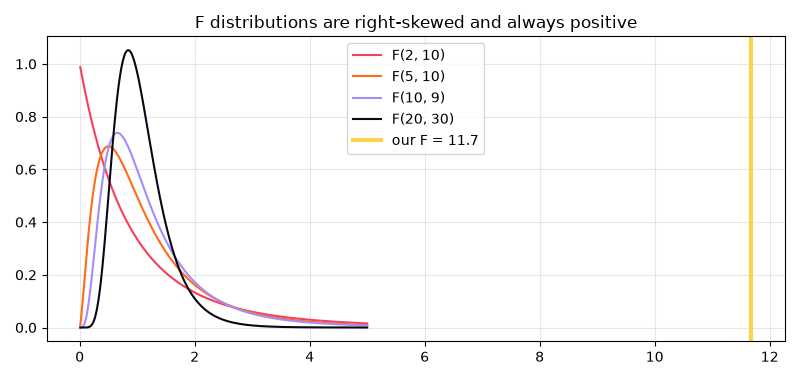

In [6]:
from IPython.display import Image, display
display(Image(filename='session-05_z_and_f_tests.png'))  # chart saved by the cell above

## Example: `session-05_problem_tutoring.py`

In [7]:
"""
Session 5 · Real-life problem: did the peer-tutoring programme work?
-------------------------------------------------------------------
PROBLEM
A department ran a 6-week peer-tutoring programme for first-year programming
students. It has:
  * pre-test and post-test scores for the same 15 tutored students
  * final exam scores for 15 tutored and 14 non-tutored students
  * a pass/fail table by group
Questions (alpha = 0.05):
  1. Did tutored students improve from pre-test to post-test?      -> paired t test
  2. Did tutored students score higher in the final exam?          -> one-sided Welch t test
  3. Is passing associated with being tutored?                     -> chi-square independence
  4. Report effect sizes and a one-paragraph recommendation.
Assumption checks (Shapiro-Wilk normality of differences, Levene) are included.

Run:  python session-05_problem_tutoring.py
"""
import numpy as np
from scipy import stats

pre = np.array([42, 55, 38, 61, 47, 50, 35, 58, 44, 52, 40, 63, 49, 46, 54])
post = np.array([51, 60, 47, 66, 55, 54, 45, 61, 52, 58, 46, 70, 53, 55, 59])
final_tut = np.array([68, 74, 61, 80, 70, 66, 58, 77, 69, 72, 63, 84, 71, 67, 75])
final_not = np.array([62, 70, 55, 66, 59, 73, 52, 64, 61, 58, 68, 57, 65, 60])
passfail = np.array([[13, 2],     # tutored:     pass, fail
                     [9, 5]])     # not tutored: pass, fail

# 1. Paired t test
d = post - pre
sw = stats.shapiro(d)
r1 = stats.ttest_rel(post, pre)
dz = d.mean() / d.std(ddof=1)
print("1) Pre vs post (same students)")
print(f"   mean gain {d.mean():.2f} points, Shapiro p = {sw.pvalue:.3f} (differences look normal)")
print(f"   t = {r1.statistic:.3f}, p = {r1.pvalue:.2e}, effect size d_z = {dz:.2f}")
ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=d.std(ddof=1) / np.sqrt(len(d)))
print(f"   95% CI for the gain: [{ci[0]:.2f}, {ci[1]:.2f}]")

# 2. Welch t test, one-sided (tutored > not tutored)
lev = stats.levene(final_tut, final_not)
r2 = stats.ttest_ind(final_tut, final_not, equal_var=False, alternative="greater")
sp = np.sqrt(((len(final_tut) - 1) * final_tut.var(ddof=1) + (len(final_not) - 1) * final_not.var(ddof=1))
             / (len(final_tut) + len(final_not) - 2))
d2 = (final_tut.mean() - final_not.mean()) / sp
print("\n2) Final exam: tutored vs not tutored")
print(f"   means {final_tut.mean():.2f} vs {final_not.mean():.2f}; Levene p = {lev.pvalue:.3f}")
print(f"   Welch t = {r2.statistic:.3f}, one-sided p = {r2.pvalue:.4f}, Cohen's d = {d2:.2f}")

# 3. Chi-square (with Fisher's exact test because some expected counts are < 5)
c2, p3, dof, exp = stats.chi2_contingency(passfail)
print("\n3) Pass/fail by group")
print("   expected counts:", exp.round(2).tolist())
print(f"   chi2 (Yates corrected) = {c2:.3f}, p = {p3:.4f}")
print(f"   Fisher's exact p = {stats.fisher_exact(passfail).pvalue:.4f}  (preferred: expected counts below 5)")

# 4. Recommendation
print(f"\n4) Recommendation: tutored students improved by about {d.mean():.1f} points (d_z = {dz:.1f}, very large)")
print(f"   and scored {final_tut.mean() - final_not.mean():.1f} points higher in the final exam (d = {d2:.2f}, large).")
rates = passfail[:, 0] / passfail.sum(axis=1)
print(f"   The pass-rate difference ({rates[0]:.0%} vs {rates[1]:.0%}) is not significant with groups this small.")
print("   Caveat: students CHOSE to join, so motivation may explain part of the gap; a randomised")
print("   pilot next semester would give stronger evidence. Continue and expand the programme.")

1) Pre vs post (same students)
   mean gain 6.53 points, Shapiro p = 0.356 (differences look normal)
   t = 11.504, p = 1.61e-08, effect size d_z = 2.97
   95% CI for the gain: [5.32, 7.75]

2) Final exam: tutored vs not tutored
   means 70.33 vs 62.14; Levene p = 0.638
   Welch t = 3.403, one-sided p = 0.0011, Cohen's d = 1.26

3) Pass/fail by group
   expected counts: [[11.38, 3.62], [10.62, 3.38]]
   chi2 (Yates corrected) = 0.947, p = 0.3304
   Fisher's exact p = 0.2148  (preferred: expected counts below 5)

4) Recommendation: tutored students improved by about 6.5 points (d_z = 3.0, very large)
   and scored 8.2 points higher in the final exam (d = 1.26, large).
   The pass-rate difference (87% vs 64%) is not significant with groups this small.
   Caveat: students CHOSE to join, so motivation may explain part of the gap; a randomised
   pilot next semester would give stronger evidence. Continue and expand the programme.


## Example: `session-05_project_test_selector.py`

In [8]:
"""
Session 5 · Mini project: an automatic 'which test should I use?' assistant
-------------------------------------------------------------------------
Choosing the right test is the hardest part for beginners. This tool:
  * takes a description of the data (types of variables, groups, pairing)
  * checks assumptions automatically (normality with Shapiro-Wilk, equal
    variance with Levene, expected counts for chi-square)
  * picks the test (and a non-parametric fallback when assumptions fail)
  * runs it and prints a plain-English report with the effect size

Run:  python session-05_project_test_selector.py
"""
import numpy as np
from scipy import stats


def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * np.var(a, ddof=1) + (len(b) - 1) * np.var(b, ddof=1)) / (len(a) + len(b) - 2))
    return (np.mean(a) - np.mean(b)) / sp


def analyse(name, a=None, b=None, mu0=None, paired=False, table=None, alpha=0.05):
    print(f"\n=== {name} ===")
    if table is not None:                                         # two categorical variables
        table = np.asarray(table)
        chi2, p, dof, exp = stats.chi2_contingency(table)
        if (exp < 5).any() and table.shape == (2, 2):
            p, test = stats.fisher_exact(table).pvalue, "Fisher's exact test (expected counts < 5)"
        else:
            test = f"chi-square test of independence (df = {dof})"
        v = np.sqrt(chi2 / (table.sum() * (min(table.shape) - 1)))
        effect = f"Cramer's V = {v:.2f}"
    elif b is None:                                               # one numeric sample vs a value
        normal = stats.shapiro(a).pvalue > alpha
        if normal:
            p, test = stats.ttest_1samp(a, mu0).pvalue, "one-sample t test"
        else:
            p, test = stats.wilcoxon(np.asarray(a) - mu0).pvalue, "Wilcoxon signed-rank (data not normal)"
        effect = f"d = {(np.mean(a) - mu0) / np.std(a, ddof=1):.2f}"
    elif paired:
        diff = np.asarray(a) - np.asarray(b)
        normal = stats.shapiro(diff).pvalue > alpha
        if normal:
            p, test = stats.ttest_rel(a, b).pvalue, "paired t test"
        else:
            p, test = stats.wilcoxon(a, b).pvalue, "Wilcoxon signed-rank (differences not normal)"
        effect = f"d_z = {diff.mean() / diff.std(ddof=1):.2f}"
    else:                                                         # two independent groups
        normal = stats.shapiro(a).pvalue > alpha and stats.shapiro(b).pvalue > alpha
        equal_var = stats.levene(a, b).pvalue > alpha
        if normal:
            p = stats.ttest_ind(a, b, equal_var=equal_var).pvalue
            test = "Student's t test (equal variances)" if equal_var else "Welch's t test (unequal variances)"
        else:
            p, test = stats.mannwhitneyu(a, b).pvalue, "Mann-Whitney U (data not normal)"
        effect = f"Cohen's d = {cohen_d(a, b):.2f}"
    verdict = "significant" if p < alpha else "not significant"
    print(f"Test chosen : {test}")
    print(f"Result      : p = {p:.4g} -> {verdict} at alpha = {alpha}; {effect}")


rng = np.random.default_rng(12)
analyse("Do students sleep less than 8 h?", a=rng.normal(6.8, 1.0, 25), mu0=8)
before_cdn = rng.normal(3.2, 0.5, 20)                     # same 20 pages measured twice
after_cdn = before_cdn - rng.normal(0.4, 0.2, 20)          # each page gets a bit faster
analyse("Website load time before/after a CDN (s)", a=before_cdn, b=after_cdn, paired=True)
analyse("Delivery minutes: rider app A vs B", a=rng.normal(32, 4, 30), b=rng.normal(35, 9, 30))
analyse("Customer spending (very skewed) in two cities", a=rng.lognormal(7, 1, 40), b=rng.lognormal(7.5, 1, 40))
analyse("Gender vs choice of elective", table=[[30, 15, 25], [20, 30, 20]])
analyse("Small trial: new drug vs placebo cured", table=[[9, 1], [4, 6]])


=== Do students sleep less than 8 h? ===
Test chosen : one-sample t test
Result      : p = 4.315e-06 -> significant at alpha = 0.05; d = -1.18

=== Website load time before/after a CDN (s) ===
Test chosen : paired t test
Result      : p = 8.737e-09 -> significant at alpha = 0.05; d_z = 2.17

=== Delivery minutes: rider app A vs B ===
Test chosen : Mann-Whitney U (data not normal)
Result      : p = 0.1188 -> not significant at alpha = 0.05; Cohen's d = -0.41

=== Customer spending (very skewed) in two cities ===
Test chosen : Mann-Whitney U (data not normal)
Result      : p = 0.006189 -> significant at alpha = 0.05; Cohen's d = -0.48

=== Gender vs choice of elective ===
Test chosen : chi-square test of independence (df = 2)
Result      : p = 0.02287 -> significant at alpha = 0.05; Cramer's V = 0.23

=== Small trial: new drug vs placebo cured ===
Test chosen : Fisher's exact test (expected counts < 5)
Result      : p = 0.05728 -> not significant at alpha = 0.05; Cramer's V = 0.42
